In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
from src.config import *
from src.utils import *
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
import joblib

#### Explore the feature extraction files for sanity check

In [2]:
train = pd.read_csv(BINARY_FEATURES_TRAIN_CSV)
val = pd.read_csv(BINARY_FEATURES_VAL_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]

print("Shapes:", train.shape, val.shape)                        # expect (5170, 232) and (3796, 232)
print("Labels train:", train["label"].value_counts().to_dict())
print("Labels val:  ", val["label"].value_counts().to_dict())
print("NaN / inf in train:", train[feature_cols].isna().sum().sum(),
      np.isinf(train[feature_cols].values).sum())
print("NaN / inf in val:  ", val[feature_cols].isna().sum().sum(),
      np.isinf(val[feature_cols].values).sum())

constant = [c for c in feature_cols if train[c].std() == 0]
print("Constant features:", constant)

Shapes: (5170, 232) (3796, 232)
Labels train: {1: 2670, 0: 2500}
Labels val:   {0: 1931, 1: 1865}
NaN / inf in train: 0 0
NaN / inf in val:   0 0
Constant features: []


### 1. Running a baseline performance of different models on our data

In [3]:
X_train = train[feature_cols].values
y_train = train["label"].values

models = {
    "LogReg":            make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "SVM (RBF)":         make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Random Forest":     RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=RANDOM_STATE),
    "HistGradBoost":     HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost":           XGBClassifier(n_estimators=500, learning_rate=0.05, n_jobs=1,
                                       random_state=RANDOM_STATE),
    "CatBoost": CatBoostClassifier(iterations=500, verbose=0, thread_count=1,
                               allow_writing_files=False, random_state=RANDOM_STATE),
}

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE) # 5-fold Cross validation

scoring = {
    "accuracy":    "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "sensitivity": make_scorer(recall_score, pos_label=1),   # others detected
    "specificity": make_scorer(recall_score, pos_label=0),   # nevus detected
    "auc":         "roc_auc",
}

results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-2)
    results[name] = {m: f'{scores[f"test_{m}"].mean():.3f} ± {scores[f"test_{m}"].std():.3f}'
                     for m in scoring}
    print(f"{name} done")

cv_results = pd.DataFrame(results).T
cv_results

LogReg done
SVM (RBF) done
Random Forest done
HistGradBoost done
XGBoost done
CatBoost done


,accuracy,balanced_accuracy,sensitivity,specificity,auc
LogReg,0.831 ± 0.009,0.831 ± 0.009,0.836 ± 0.018,0.827 ± 0.015,0.904 ± 0.010
SVM (RBF),0.852 ± 0.011,0.852 ± 0.011,0.858 ± 0.019,0.845 ± 0.015,0.917 ± 0.009
Random Forest,0.842 ± 0.014,0.842 ± 0.014,0.844 ± 0.023,0.840 ± 0.016,0.913 ± 0.009
HistGradBoost,0.847 ± 0.006,0.847 ± 0.005,0.853 ± 0.019,0.841 ± 0.013,0.918 ± 0.007
XGBoost,0.851 ± 0.008,0.851 ± 0.009,0.857 ± 0.011,0.844 ± 0.022,0.922 ± 0.006
CatBoost,0.848 ± 0.009,0.848 ± 0.010,0.853 ± 0.016,0.843 ± 0.020,0.921 ± 0.009


In [5]:
# Save the results to a CSV file
cv_results.to_csv(RESULTS_DIR / "cv_baseline_default_models.csv")

It would be very interesting to check the confusion matrices of each evaluated model, to see which classes are being confused with each other. This can help us understand the strengths and weaknesses of each model, and guide us in selecting the best model for our task.

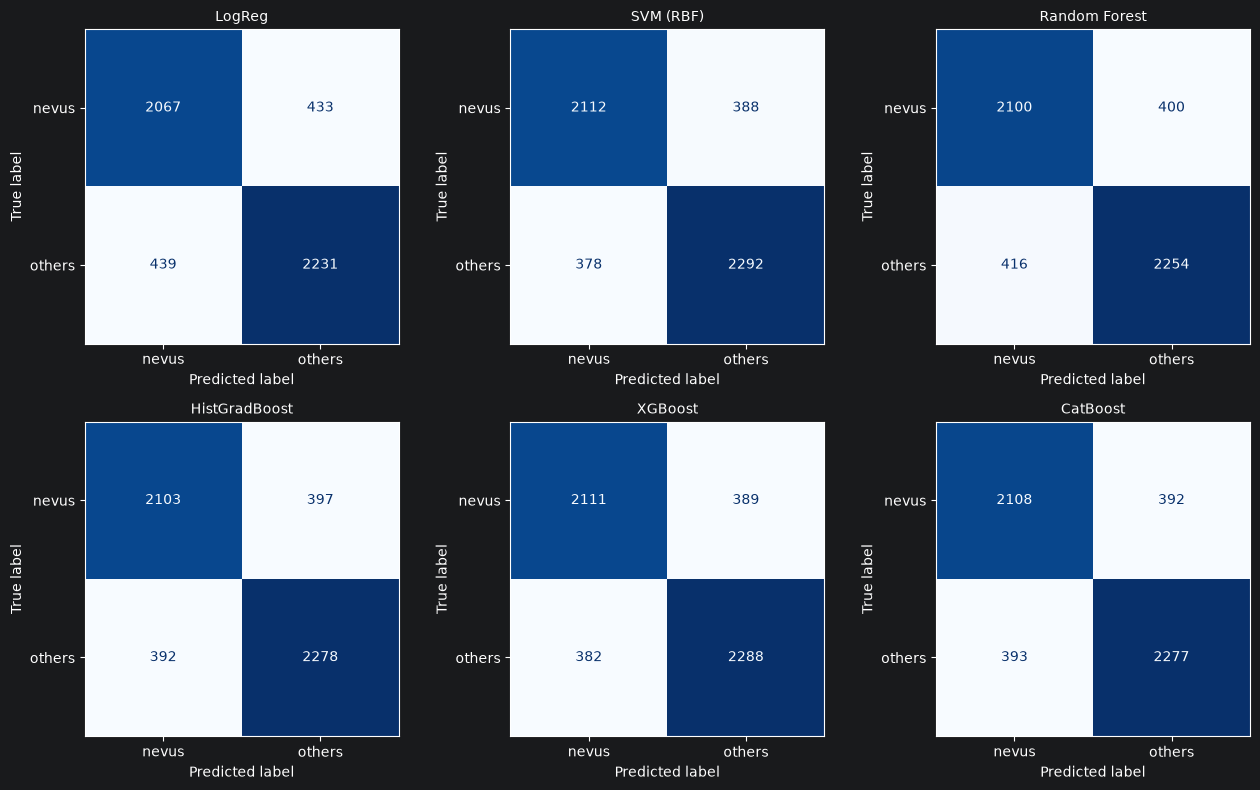

In [6]:
def oof_scores(model):
    """Out-of-fold scores for 'others' + the threshold that turns them into 0/1."""
    if hasattr(model, "predict_proba"):
        proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-2)
        return proba[:, 1], 0.5
    # SVM without probability=True only has a decision function (> 0 means "others")
    return cross_val_predict(model, X_train, y_train, cv=cv, method="decision_function", n_jobs=-2), 0.0

scores_default = {name: oof_scores(m) for name, m in models.items()}

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, (scores, threshold)) in zip(axes.flat, scores_default.items()):
    plot_confusion(ax, y_train, (scores > threshold).astype(int), name)
plt.tight_layout()
plt.show()

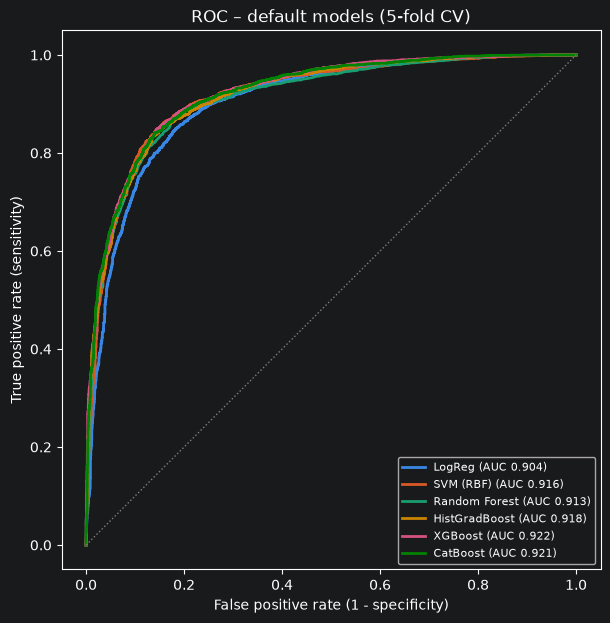

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
for name, (scores, _) in scores_default.items():
    plot_roc(ax, y_train, scores, name, MODEL_COLORS[name])
finish_roc(ax, "ROC – default models (5-fold CV)")
plt.show()

### 2. Fine-tune the models with hyperparameter search

In [9]:
def tune(estimator, param_dist, n_iter):
    """Random search over param_dist with the same 5-fold CV and metrics as before."""
    search = RandomizedSearchCV(
        estimator, param_dist, n_iter=n_iter,
        scoring=scoring, refit="balanced_accuracy",      # compute all metrics, choose the best by accuracy
        cv=cv, n_jobs=-2, random_state=RANDOM_STATE, verbose=2,
    )
    search.fit(X_train, y_train)
    return search


def summarize(search):
    """Mean ± std of every metric for the best combination found."""
    i = search.best_index_
    r = search.cv_results_
    return {m: f'{r[f"mean_test_{m}"][i]:.3f} ± {r[f"std_test_{m}"][i]:.3f}' for m in scoring}

In [10]:
param_svm = {
    "svc__C":     loguniform(0.1, 100),     # higher = fewer training errors allowed
    "svc__gamma": loguniform(1e-4, 1e-1),   # higher = more local, wigglier decision boundary
}

param_xgb = {
    "n_estimators":     randint(200, 600),
    "learning_rate":    loguniform(0.03, 0.2),
    "max_depth":        randint(3, 8),
    "subsample":        uniform(0.6, 0.4),   # 0.6 - 1.0: fraction of images per tree
    "colsample_bytree": uniform(0.4, 0.6),   # 0.4 - 1.0: fraction of features per tree
    "min_child_weight": randint(1, 10),
}

param_cat = {
    "iterations":    randint(200, 600),
    "learning_rate": loguniform(0.03, 0.2),
    "depth":         randint(4, 8),
    "l2_leaf_reg":   loguniform(1, 10),     # regularisation strength
}

In [11]:
search_svm = tune(models["SVM (RBF)"], param_svm, n_iter=40)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


In [12]:
search_xgb = tune(models["XGBoost"], param_xgb, n_iter=20) # 20 iterations is good enough

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [13]:
search_cat = tune(models["CatBoost"], param_cat, n_iter=15) # We used fewer iterations because it's slower to train

Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [20]:
searches = {"SVM (RBF)": search_svm, "XGBoost": search_xgb, "CatBoost": search_cat}
scores_tuned   = {name: oof_scores(s.best_estimator_) for name, s in searches.items()}
tuned_rows = {f"{name} (tuned)": summarize(s) for name, s in searches.items()}
comparison = pd.concat([cv_results.loc[list(searches)], pd.DataFrame(tuned_rows).T])
comparison

,accuracy,balanced_accuracy,sensitivity,specificity,auc
SVM (RBF),0.852 ± 0.011,0.852 ± 0.011,0.858 ± 0.019,0.845 ± 0.015,0.917 ± 0.009
XGBoost,0.851 ± 0.008,0.851 ± 0.009,0.857 ± 0.011,0.844 ± 0.022,0.922 ± 0.006
CatBoost,0.848 ± 0.009,0.848 ± 0.010,0.853 ± 0.016,0.843 ± 0.020,0.921 ± 0.009
SVM (RBF) (tuned),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
XGBoost (tuned),0.852 ± 0.009,0.851 ± 0.010,0.857 ± 0.009,0.846 ± 0.021,0.922 ± 0.007
CatBoost (tuned),0.851 ± 0.011,0.851 ± 0.011,0.854 ± 0.014,0.849 ± 0.023,0.924 ± 0.008


In [18]:
for name, s in searches.items():
    print(name, s.best_params_)

comparison.to_csv(RESULTS_DIR / "cv_tuned_vs_default.csv")

SVM (RBF) {'svc__C': np.float64(11.290133559092672), 'svc__gamma': np.float64(0.0020914981329035616)}
XGBoost {'colsample_bytree': np.float64(0.685222133909267), 'learning_rate': np.float64(0.08733914216812769), 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 430, 'subsample': np.float64(0.7641531692142519)}
CatBoost {'depth': 7, 'iterations': 470, 'l2_leaf_reg': np.float64(2.858051065806936), 'learning_rate': np.float64(0.13305603957582046)}


Plot the Confusion Matrices for the tuned models, and compare them with the default ones.

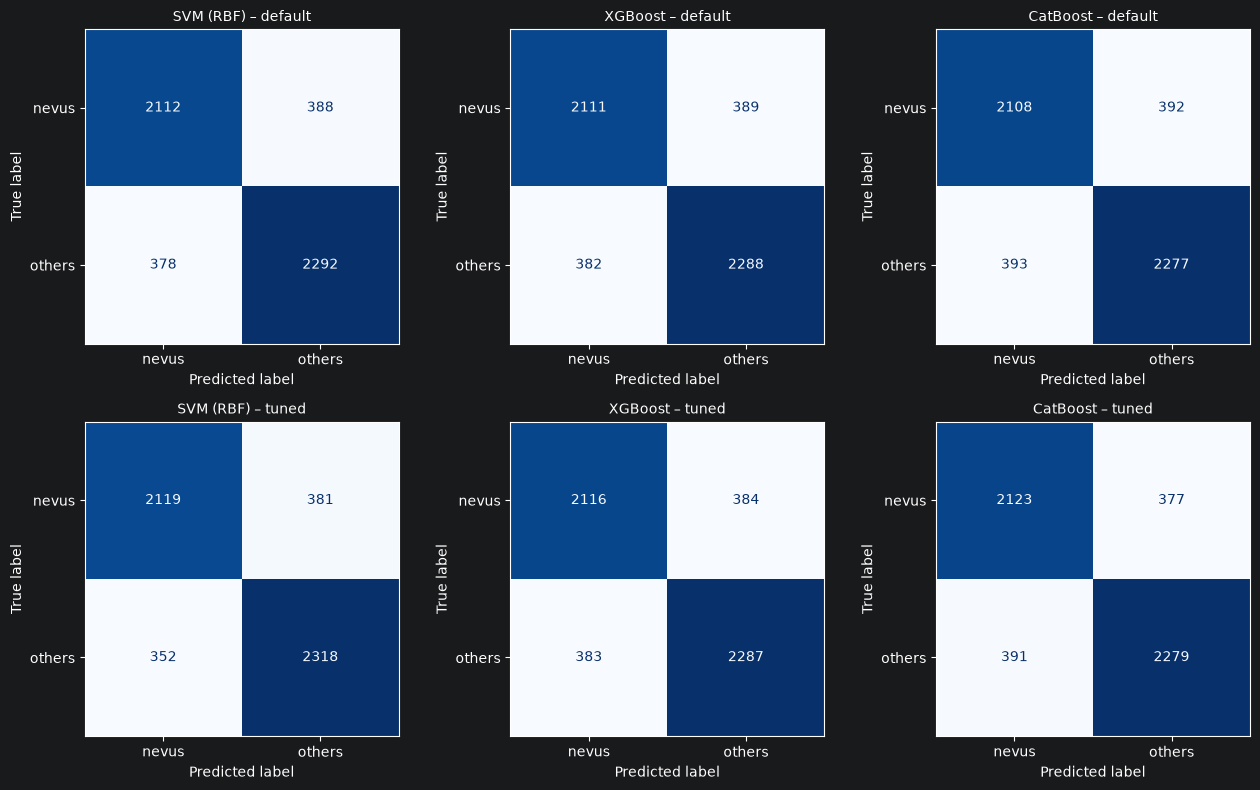

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, name in enumerate(searches):
    for row, (label, scores_dict) in enumerate([("default", scores_default), ("tuned", scores_tuned)]):
        scores, threshold = scores_dict[name]
        plot_confusion(axes[row, col], y_train, (scores > threshold).astype(int), f"{name} – {label}")
plt.tight_layout()
plt.show()

Plot the ROC curves for the tuned models, and compare them with the default ones.

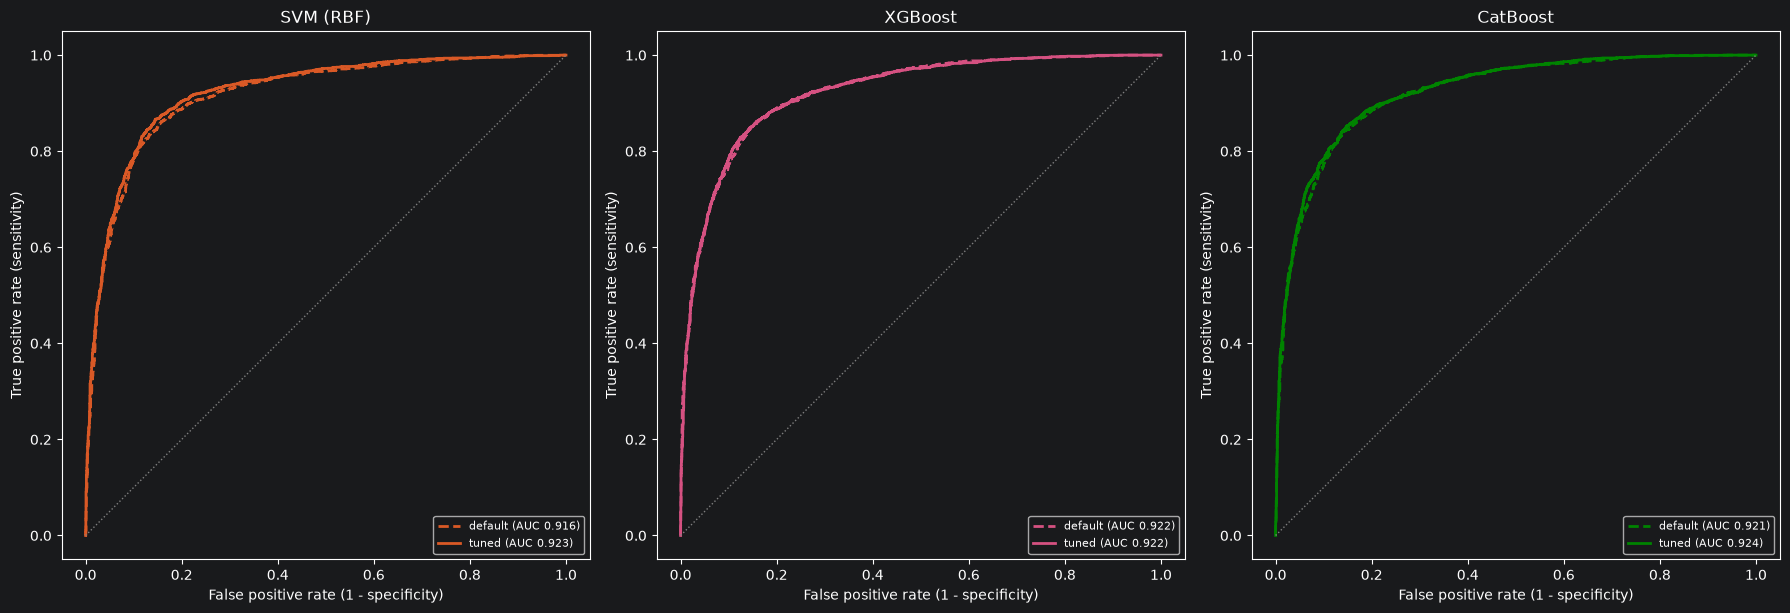

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, searches):
    plot_roc(ax, y_train, scores_default[name][0], "default", MODEL_COLORS[name], linestyle="--")
    plot_roc(ax, y_train, scores_tuned[name][0],   "tuned",   MODEL_COLORS[name], linestyle="-")
    finish_roc(ax, name)
plt.tight_layout()
plt.show()

After tuning the hyperparameters for each of the best performing models in the baseline, we see that the effect of such process does not improve by a lot the performance. **In the case of SVM, balanced Accuracy improved from 0.853 to 0.858**, resulting in the best performing algorithm in terms of accuracy.

CatBoost is also a very good performing model, but is we stick strictly to balanced accuracy then SVM (RBF kernel) is the best model for our task. In terms of sensitivity, CatBoost is the best performing model, but it is not as good as SVM in terms of specificity. This means that CatBoost is better at detecting "others" but worse at detecting "nevus", while SVM is better at detecting "nevus" but worse at detecting "others". Depending on the application, one may prefer one model over the other. In our case, we will stick to SVM as the best performing model.

### Save the best model
In our case, we found that SVM after hyperparameter tuning performed the best, so we will save it for later use (as well as the scaler).

In [19]:
MODELS_DIR.mkdir(exist_ok=True)

bundle = {
    "model":        searches["SVM (RBF)"].best_estimator_,   # scaler + SVM, trained on train subset
    "feature_cols": feature_cols,                             # column order the model expects
    "best_params":  searches["SVM (RBF)"].best_params_,
    "cv_scores":    summarize(searches["SVM (RBF)"]),
}
joblib.dump(bundle, MODELS_DIR / "binary_svm_tuned_v1.joblib")

['C:\\Users\\ferra\\MIC\\2n_any_UdG\\CADx\\Project\\Project-1-CAD\\models\\binary_svm_tuned_v1.joblib']

Use this code here to load & use the saved model after:

`bundle = joblib.load(MODELS_DIR / "binary_svm_tuned_v1.joblib")`

`model = bundle["model"]`

`predictions = model.predict(val[bundle["feature_cols"]].values)`